In [1]:
import pandas as pd

x_train = pd.read_csv('x_train.csv')
x_test = pd.read_csv('x_test.csv')
y_train = pd.read_csv('y_train.csv').values.ravel()  # Flatten the array to 1D
y_test = pd.read_csv('y_test.csv').values.ravel()  # Flatten the array to 1D

Train the logistic regression baseline

In [2]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(max_iter=10000)
log_reg.fit(x_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",10000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use 

In [3]:
import numpy as np
import pandas as pd

coef_table = pd.DataFrame({
    "Feature": x_train.columns,
    "Coefficient": log_reg.coef_[0],
    "Odds Ratio": np.exp(log_reg.coef_[0])
})

coef_table["Percent change in odds"] = (
    (coef_table["Odds Ratio"] - 1) * 100
)
coef_table

print("Intercept: ", log_reg.intercept_[0])

Intercept:  1.198220533850249


Generate Predictions

In [4]:
y_pred = log_reg.predict(x_test) #Prediction for 0/1
y_pred_proba = log_reg.predict_proba(x_test)[:, 1] #Prediction for probability of 1

Evaluation

In [5]:
from sklearn.metrics import accuracy_score, roc_auc_score

accuracy = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_pred_proba)

print(f"Accuracy: {accuracy:.4f}")
print(f"AUC-ROC: {auc:.4f}")

Accuracy: 0.6159
AUC-ROC: 0.6365


Naive Baseline

In [6]:
naive_rate = y_train.mean()
naive_pred = [naive_rate] * len(y_train)

naive_accuracy = roc_auc_score(y_train, naive_pred)
print(f"Naive baseline accuracy: {naive_accuracy:.4f}")


Naive baseline accuracy: 0.5000


In [7]:
import joblib
joblib.dump(log_reg, "log_reg_baseline.pk1")

['log_reg_baseline.pk1']

XGBoost model

In [8]:
import pandas as pd

x_train = pd.read_csv('x_train.csv')
x_test = pd.read_csv('x_test.csv')
y_train = pd.read_csv('y_train.csv').values.ravel()
y_test = pd.read_csv('y_test.csv').values.ravel()

In [9]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators = 200,
    max_depth = 6,
    learning_rate = 0.1,
    eval_metric = 'logloss',
    random_state = 42,
)

xgb_model.fit(x_train, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


Generate Predictions

In [10]:
y_pred_xgb = xgb_model.predict(x_test)
y_proba_xgb = xgb_model.predict_proba(x_test)[:, 1]

Evaluate the predictions

In [11]:
from sklearn.metrics import roc_auc_score, accuracy_score

acc_xgb = accuracy_score(y_test, y_pred_xgb)
auc_xgb = roc_auc_score(y_test, y_proba_xgb)

print(f"Accuracy: {acc_xgb:.4f}")
print(f"AUC: {auc_xgb:.4f}")

Accuracy: 0.6116
AUC: 0.6343


Comparing all three sides

In [12]:
print(f"Naive baseline AUC: {naive_accuracy:.4f}")
print(f"Logistic regressions AUC: {accuracy:.4f}")
print(f"XGBoost AUC: {auc_xgb:.4f}")

Naive baseline AUC: 0.5000
Logistic regressions AUC: 0.6159
XGBoost AUC: 0.6343


In [13]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, brier_score_loss, log_loss
import joblib


rf_model = RandomForestClassifier(n_estimators=100, max_depth=16,
                                  min_samples_leaf=20,
                                  n_jobs=-1, random_state=42)
rf_model.fit(x_train, y_train)
proba_rf = rf_model.predict_proba(x_test)[:, 1]
joblib.dump(rf_model, 'random_forest.pkl', compress=3)

models = {
    'Constant Baseline': np.full(len(y_test), y_train.mean()),
    'Logistic Regression': y_pred_proba,
    'Random Forest': proba_rf,
    'XGBoost': y_proba_xgb,
}

rows = []
for name, proba in models.items():
    rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, (proba >= 0.5).astype(int)),
        'AUC': roc_auc_score(y_test, proba),
        'Brier Score': brier_score_loss(y_test, proba),
        'Log Loss': log_loss(y_test, proba),
    })

results = pd.DataFrame(rows).round(4)
print(results.to_string(index=False))

              Model  Accuracy    AUC  Brier Score  Log Loss
  Constant Baseline    0.5333 0.5000       0.2489    0.6910
Logistic Regression    0.6159 0.6365       0.2306    0.6514
      Random Forest    0.6161 0.6412       0.2294    0.6491
            XGBoost    0.6116 0.6343       0.2307    0.6514


Checks feature importance. Looking at which features the model relied on.

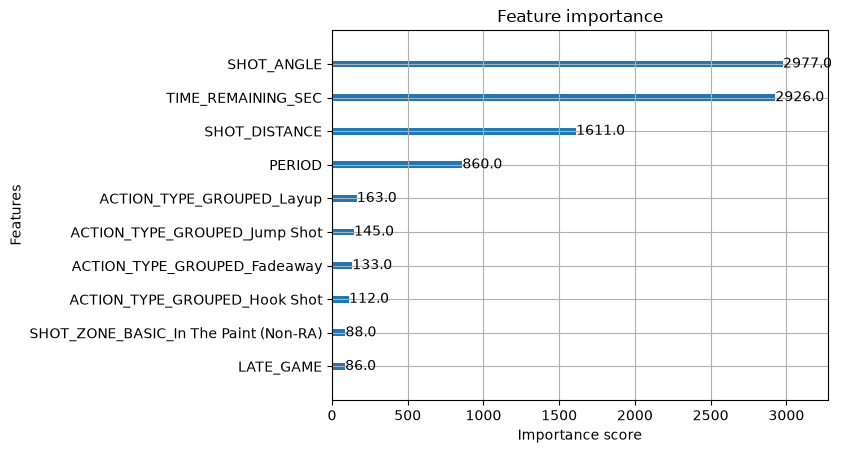

In [14]:
import matplotlib.pyplot as plt
from xgboost import plot_importance

plot_importance(xgb_model, max_num_features = 10)
plt.show()

In [15]:
xgb_model.save_model("xgb_model.json")

Generate Calibration

prob_pred is what my model predicted for each bin (e.g., "40%chance"), and prob_true is what actually happended in that bin (e.g., "38% of these shots went in"). The closer those two numbers are, the better calibrated my model is.

In [16]:
from sklearn.calibration import calibration_curve

# Calibration curves for all fitted models
prob_true_lr, prob_pred_lr = calibration_curve(y_test, y_pred_proba, n_bins=10)
prob_true_rf, prob_pred_rf = calibration_curve(y_test, proba_rf, n_bins=10)
prob_true_xgb, prob_pred_xgb = calibration_curve(y_test, y_proba_xgb, n_bins=10)

Plot both on the "perfect calibration" line

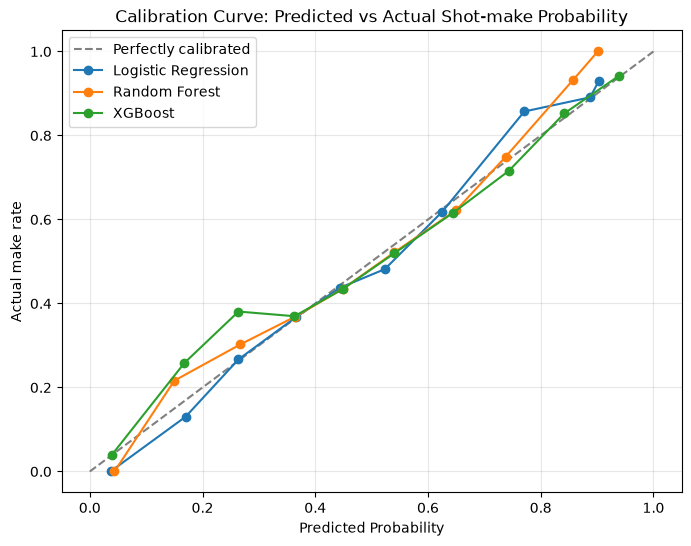

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

# Perfect calibration reference line
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfectly calibrated')

# Model calibration curves
plt.plot(prob_pred_lr, prob_true_lr, marker='o', label='Logistic Regression')
plt.plot(prob_pred_rf, prob_true_rf, marker='o', label='Random Forest')
plt.plot(prob_pred_xgb, prob_true_xgb, marker='o', label='XGBoost')

plt.xlabel('Predicted Probability')
plt.ylabel('Actual make rate')
plt.title('Calibration Curve: Predicted vs Actual Shot-make Probability')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig('calibration_curve.png', dpi=150, bbox_inches='tight')
plt.show()

Calibration Table

In [18]:
def calibration_table(y_true, proba, n_bins=10):
    edges = np.linspace(0, 1, n_bins +1)
    idx = np.clip(np.digitize(proba, edges) - 1, 0, n_bins - 1)
    out = []
    for b in range(n_bins):
        m = idx == b
        if m.sum() == 0:
            continue
        out.append({
            'bin': f'{edges[b]:.1f}-{edges[b+1]:.1f}',
            'n_shots': int(m.sum()),
            'mean_pred': proba[m].mean(),
            'actual_rate': y_true[m].mean(),
            'gap': proba[m].mean() - y_true[m].mean()
        })
    return pd.DataFrame(out).round(4)

calibration_table(y_test, y_proba_xgb)

,bin,n_shots,mean_pred,actual_rate,gap
0,0.0-0.1,77,0.0387,0.0390,-0.0002
1,0.1-0.2,116,0.1680,0.2586,-0.0907
2,0.2-0.3,730,0.2638,0.3808,-0.1170
3,0.3-0.4,6878,0.3631,0.3697,-0.0066
4,0.4-0.5,6366,0.4486,0.4342,0.0144
5,0.5-0.6,2771,0.5400,0.5193,0.0207
6,0.6-0.7,1416,0.6452,0.6165,0.0287
7,0.7-0.8,1006,0.7433,0.7157,0.0276
8,0.8-0.9,312,0.8418,0.8526,-0.0108
9,0.9-1.0,558,0.9395,0.9427,-0.0032


Random forest model